In [1]:

# Step 1: Import required libraries

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

print("OpenCV Version:", cv2.__version__)
print("Environment Setup Successful!")


PyTorch Version: 2.14.1+cu130
GPU Available: True
GPU Name: Tesla T4
OpenCV Version: 4.14.0
Environment Setup Successful!


In [2]:

# Step 2: Download TrashCan Dataset

!pip install -q gdown pycocotools

import os

os.makedirs("/content/dataset", exist_ok=True)

print("Dataset folder created successfully!")


Dataset folder created successfully!


In [3]:

!pip -q install gdown

import gdown
import zipfile
import os

FILE_ID = "1-vq93J-_CXOM5hXbvCfzEz03jukxp7mv"

# Download dataset
gdown.download(
    id=FILE_ID,
    output="/content/dataset.zip",
    quiet=False
)

# Extract dataset
os.makedirs("/content/dataset", exist_ok=True)

with zipfile.ZipFile("/content/dataset.zip", "r") as zip_ref:
    zip_ref.extractall("/content/dataset")

print("DATASET DOWNLOADED AND EXTRACTED SUCCESSFULLY!")


Downloading...
From (original): https://drive.google.com/uc?id=1-vq93J-_CXOM5hXbvCfzEz03jukxp7mv
From (redirected): https://drive.google.com/uc?id=1-vq93J-_CXOM5hXbvCfzEz03jukxp7mv&confirm=t&uuid=c1bf91df-92c7-4159-b1a7-3f1398680459
To: /content/dataset.zip
100%|██████████| 553M/553M [00:07<00:00, 75.5MB/s]


DATASET DOWNLOADED AND EXTRACTED SUCCESSFULLY!


In [4]:
import os

DATASET_DIR = "/content/dataset"

for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)

dataset/
  dataset/
    README.txt
    instance_version/
      instances_train_trashcan.json
      README.txt
      instances_val_trashcan.json
    scripts/
      trash_can_coco.py
    material_version/
      instances_train_trashcan.json
      README.txt
      instances_val_trashcan.json
    original_data/
      README.txt


In [5]:
import os
import json

BASE = "/content/dataset/dataset"

# Find image folders
for root, dirs, files in os.walk(BASE):
    images = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if images:
        print("Image folder:", root)
        print("Number of images:", len(images))
        print("Sample:", images[:3])

# Read training annotations
annotation_path = os.path.join(
    BASE, "instance_version", "instances_train_trashcan.json"
)

with open(annotation_path, "r") as f:
    data = json.load(f)

print("\nTotal images:", len(data["images"]))
print("Total annotations:", len(data["annotations"]))
print("Total categories:", len(data["categories"]))
print("Categories:", [c["name"] for c in data["categories"]])

Image folder: /content/dataset/dataset/instance_version/train
Number of images: 6065
Sample: ['vid_000112_frame0000026.jpg', 'vid_000332_frame0000125.jpg', 'vid_000270_frame0000047.jpg']
Image folder: /content/dataset/dataset/instance_version/val
Number of images: 1147
Sample: ['vid_000251_frame0000030.jpg', 'vid_000075_frame0000070.jpg', 'vid_000132_frame0000092.jpg']
Image folder: /content/dataset/dataset/material_version/train
Number of images: 6008
Sample: ['vid_000112_frame0000026.jpg', 'vid_000332_frame0000125.jpg', 'vid_000270_frame0000047.jpg']
Image folder: /content/dataset/dataset/material_version/val
Number of images: 1204
Sample: ['vid_000080_frame0000029.jpg', 'vid_000075_frame0000070.jpg', 'vid_000132_frame0000092.jpg']
Image folder: /content/dataset/dataset/original_data/images
Number of images: 7212
Sample: ['vid_000112_frame0000026.jpg', 'vid_000332_frame0000125.jpg', 'vid_000270_frame0000047.jpg']

Total images: 6065
Total annotations: 9540
Total categories: 22
Catego

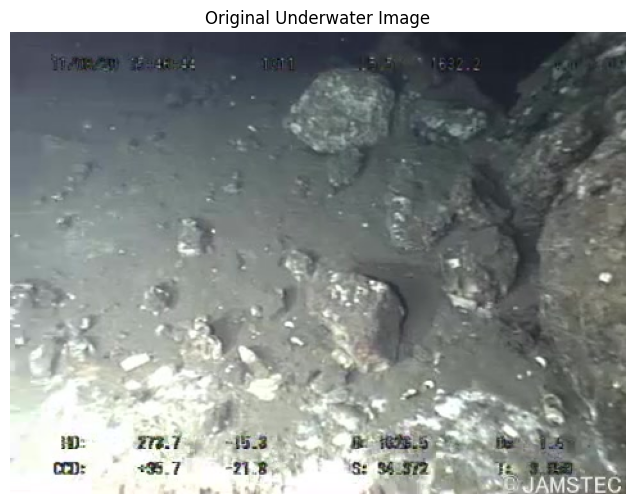

Image: vid_000112_frame0000026.jpg
Image shape: (360, 480, 3)


In [6]:
import cv2
import matplotlib.pyplot as plt
import os

IMAGE_DIR = "/content/dataset/dataset/original_data/images"

images = [
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

img_path = os.path.join(IMAGE_DIR, images[0])

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(img)
plt.title("Original Underwater Image")
plt.axis("off")
plt.show()

print("Image:", images[0])
print("Image shape:", img.shape)

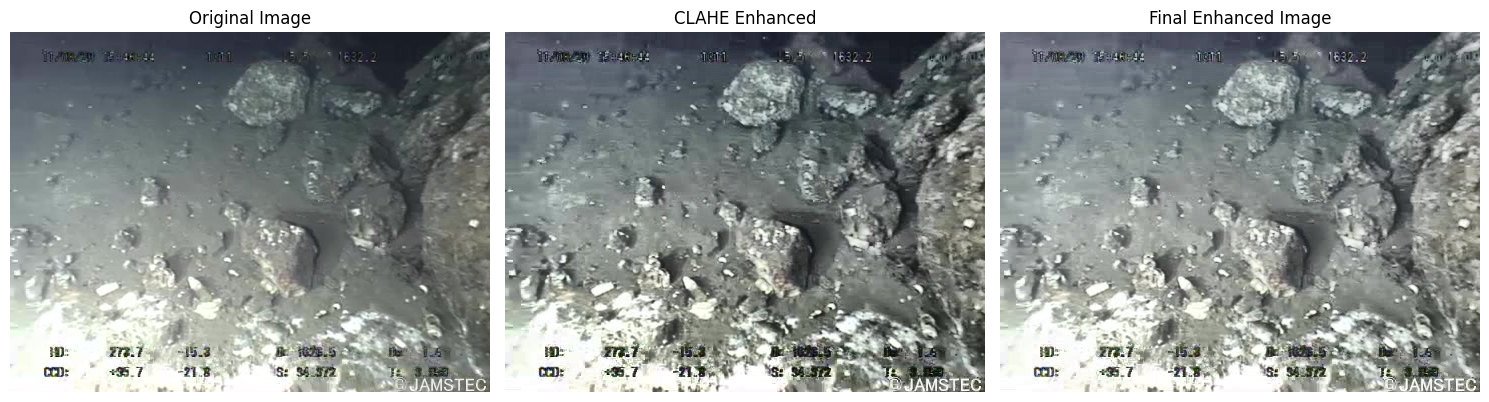

In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Original image
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 1. CLAHE Contrast Enhancement
lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
l, a, b = cv2.split(lab)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced_l = clahe.apply(l)
enhanced_lab = cv2.merge((enhanced_l, a, b))
clahe_img = cv2.cvtColor(
    enhanced_lab, cv2.COLOR_LAB2RGB
)

# 2. Gamma Correction
gamma = 1.3
gamma_img = np.clip(
    255 * (clahe_img / 255.0) ** (1 / gamma),
    0, 255
).astype(np.uint8)

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(clahe_img)
plt.title("CLAHE Enhanced")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gamma_img)
plt.title("Final Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()


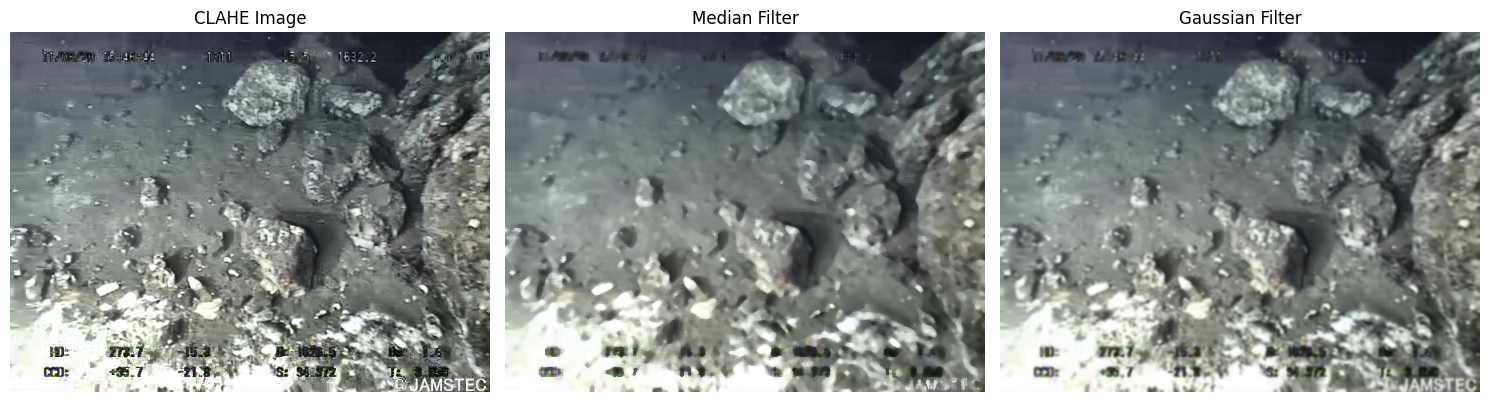

In [8]:

# STEP 5: Noise Removal

import cv2
import matplotlib.pyplot as plt

# Median Filtering
median_img = cv2.medianBlur(clahe_img, 5)

# Gaussian Filtering
gaussian_img = cv2.GaussianBlur(
    clahe_img, (5, 5), 0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(clahe_img)
plt.title("CLAHE Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(median_img)
plt.title("Median Filter")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gaussian_img)
plt.title("Gaussian Filter")
plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:
!pip install -q ultralytics pycocotools opencv-python matplotlib

In [10]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

BASE = "/content/dataset/dataset"

TRAIN_IMG = os.path.join(BASE, "instance_version/train")
VAL_IMG = os.path.join(BASE, "instance_version/val")

TRAIN_JSON = os.path.join(
    BASE, "instance_version/instances_train_trashcan.json"
)

VAL_JSON = os.path.join(
    BASE, "instance_version/instances_val_trashcan.json"
)

with open(TRAIN_JSON) as f:
    train_data = json.load(f)

with open(VAL_JSON) as f:
    val_data = json.load(f)

print("Training images:", len(train_data["images"]))
print("Validation images:", len(val_data["images"]))
print("Categories:")

for c in train_data["categories"]:
    print(c["id"], c["name"])

Training images: 6065
Validation images: 1147
Categories:
1 rov
2 plant
3 animal_fish
4 animal_starfish
5 animal_shells
6 animal_crab
7 animal_eel
8 animal_etc
9 trash_clothing
10 trash_pipe
11 trash_bottle
12 trash_bag
13 trash_snack_wrapper
14 trash_can
15 trash_cup
16 trash_container
17 trash_unknown_instance
18 trash_branch
19 trash_wreckage
20 trash_tarp
21 trash_rope
22 trash_net


In [11]:
import shutil
from pathlib import Path

OUTPUT = "/content/yolo_dataset"

for split in ["train", "val"]:
    os.makedirs(f"{OUTPUT}/images/{split}", exist_ok=True)
    os.makedirs(f"{OUTPUT}/labels/{split}", exist_ok=True)

# Select marine waste categories
categories = train_data["categories"]

waste_categories = [
    c for c in categories
    if "trash" in c["name"].lower()
]

print("Selected waste categories:",
      [c["name"] for c in waste_categories])

if not waste_categories:
    raise ValueError("No trash category found. Check category names.")

cat_map = {
    c["id"]: i for i, c in enumerate(waste_categories)
}

def convert_annotations(data, image_dir, split):
    image_map = {img["id"]: img for img in data["images"]}

    for ann in data["annotations"]:

        if ann["category_id"] not in cat_map:
            continue

        img_info = image_map[ann["image_id"]]
        filename = img_info["file_name"]

        src = os.path.join(image_dir, filename)

        if not os.path.exists(src):
            continue

        width = img_info["width"]
        height = img_info["height"]

        segmentation = ann.get("segmentation", [])

        if isinstance(segmentation, dict):
            from pycocotools import mask as mask_utils

            mask = mask_utils.decode(
                mask_utils.frPyObjects(segmentation, height, width)
                if isinstance(segmentation.get("counts"), list)
                else segmentation
            )
            if mask.ndim == 3:
                mask = mask[:, :, 0]

            contours, _ = cv2.findContours(
                mask.astype(np.uint8),
                cv2.RETR_EXTERNAL,
                cv2.CHAIN_APPROX_SIMPLE
            )

            polygons = [
                c.flatten().tolist()
                for c in contours if len(c) >= 3
            ]

        else:
            polygons = segmentation

        label_lines = []

        for polygon in polygons:
            points = np.array(polygon).reshape(-1, 2)

            if len(points) < 3:
                continue

            points[:, 0] /= width
            points[:, 1] /= height

            points = np.clip(points, 0, 1)

            class_id = cat_map[ann["category_id"]]

            coords = " ".join(
                f"{v:.6f}" for v in points.flatten()
            )

            label_lines.append(f"{class_id} {coords}")

        if not label_lines:
            continue

        dst = f"{OUTPUT}/images/{split}/{Path(filename).name}"

        if not os.path.exists(dst):
            shutil.copy2(src, dst)

        label_name = Path(filename).stem + ".txt"

        label_path = f"{OUTPUT}/labels/{split}/{label_name}"

        with open(label_path, "a") as f:
            f.write("\n".join(label_lines) + "\n")

convert_annotations(train_data, TRAIN_IMG, "train")
convert_annotations(val_data, VAL_IMG, "val")

print("YOLO segmentation conversion complete!")
print("Train images:", len(os.listdir(f"{OUTPUT}/images/train")))
print("Validation images:", len(os.listdir(f"{OUTPUT}/images/val")))

Selected waste categories: ['trash_clothing', 'trash_pipe', 'trash_bottle', 'trash_bag', 'trash_snack_wrapper', 'trash_can', 'trash_cup', 'trash_container', 'trash_unknown_instance', 'trash_branch', 'trash_wreckage', 'trash_tarp', 'trash_rope', 'trash_net']
YOLO segmentation conversion complete!
Train images: 4121
Validation images: 941


In [12]:
import yaml

names = [c["name"] for c in waste_categories]

config = {
    "path": OUTPUT,
    "train": "images/train",
    "val": "images/val",
    "nc": len(names),
    "names": names
}

with open(f"{OUTPUT}/data.yaml", "w") as f:
    yaml.dump(config, f, sort_keys=False)

print("Dataset configuration created!")
print(config)

Dataset configuration created!
{'path': '/content/yolo_dataset', 'train': 'images/train', 'val': 'images/val', 'nc': 14, 'names': ['trash_clothing', 'trash_pipe', 'trash_bottle', 'trash_bag', 'trash_snack_wrapper', 'trash_can', 'trash_cup', 'trash_container', 'trash_unknown_instance', 'trash_branch', 'trash_wreckage', 'trash_tarp', 'trash_rope', 'trash_net']}


In [13]:
from ultralytics import YOLO

model = YOLO("yolo11n-seg.pt")

results = model.train(
    data=f"{OUTPUT}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=10,
    project="/content/underwater_project",
    name="waste_segmentation",
    save=True,
    plots=True
)

print("Training completed!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0,

In [14]:
best_model = YOLO(
    "/content/underwater_project/waste_segmentation/weights/best.pt"
)

metrics = best_model.val(
    data=f"{OUTPUT}/data.yaml",
    imgsz=640,
    device=0
)

print("Segmentation mAP50:", metrics.seg.map50)
print("Segmentation mAP50-95:", metrics.seg.map)
print("Box mAP50:", metrics.box.map50)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,852,626 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 674.7±243.1 MB/s, size: 19.0 KB)
val: Scanning /content/yolo_dataset/labels/val.cache... 941 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 941/941 219.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 59/59 4.2it/s 14.0s
                   all        941       1989      0.765      0.542      0.588      0.454      0.771      0.533      0.584      0.363
        trash_clothing         17         21      0.793      0.286      0.365      0.315      0.806      0.286      0.365      0.285
            trash_pipe         42         60      0.732      0.933      0.913      0.767      0.747       0.95      0.936      0.394
          trash_bottle         26      


image 1/1 /content/yolo_dataset/images/val/vid_000049_frame0000011.jpg: 384x640 1 trash_unknown_instance, 14.1ms
Speed: 6.6ms preprocess, 14.1ms inference, 20.6ms postprocess per image at shape (1, 3, 384, 640)


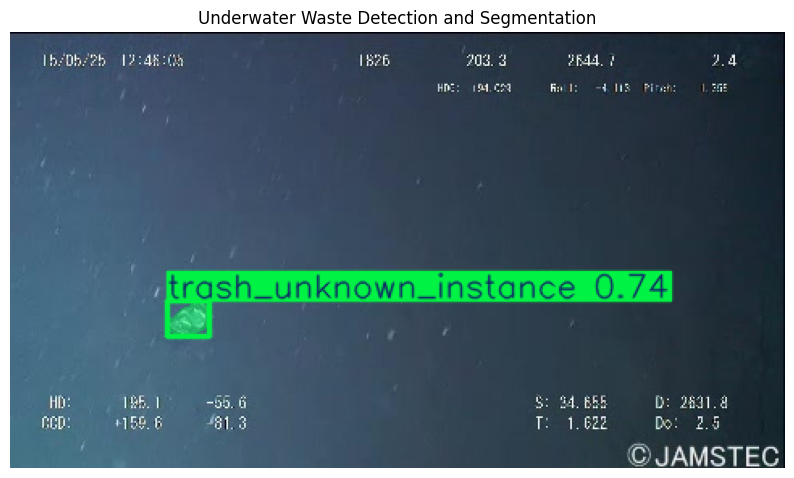


image 1/1 /content/yolo_dataset/images/val/vid_000090_frame0000049.jpg: 384x640 1 trash_net, 16.2ms
Speed: 2.0ms preprocess, 16.2ms inference, 2.8ms postprocess per image at shape (1, 3, 384, 640)


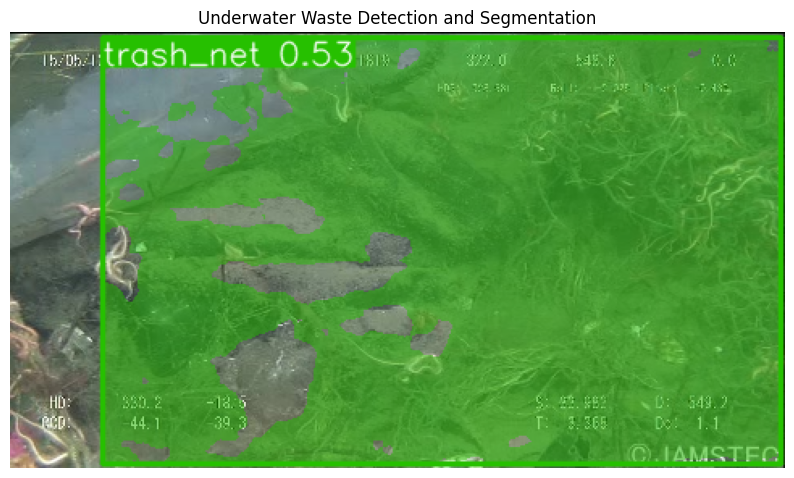


image 1/1 /content/yolo_dataset/images/val/vid_000144_frame0000024.jpg: 384x640 1 trash_bag, 49.8ms
Speed: 7.2ms preprocess, 49.8ms inference, 18.6ms postprocess per image at shape (1, 3, 384, 640)


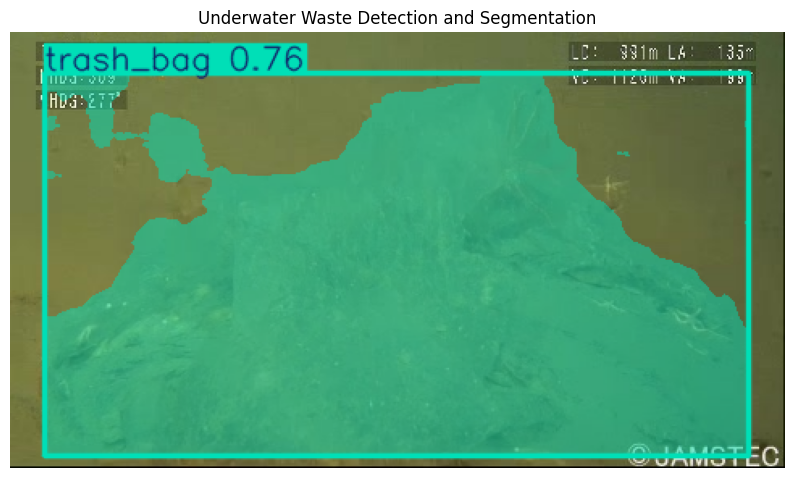


image 1/1 /content/yolo_dataset/images/val/vid_000038_frame0000001.jpg: 384x640 1 trash_unknown_instance, 30.1ms
Speed: 2.5ms preprocess, 30.1ms inference, 3.1ms postprocess per image at shape (1, 3, 384, 640)


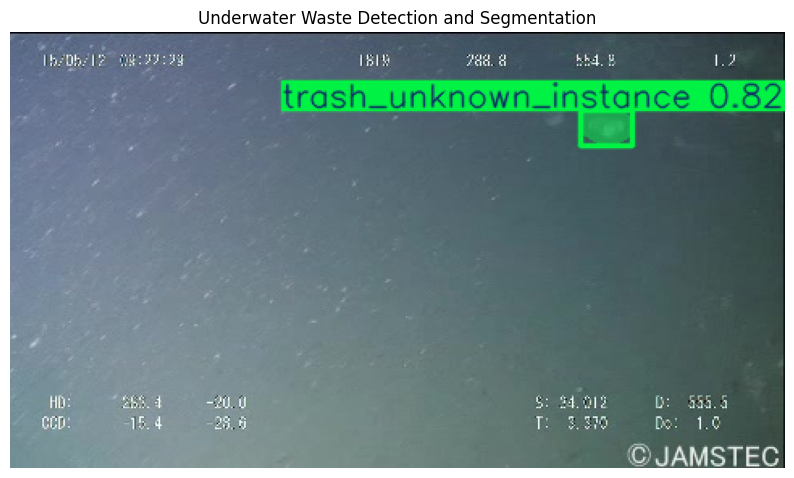

In [15]:
import random
import glob

test_images = glob.glob(f"{OUTPUT}/images/val/*")

sample_images = random.sample(
    test_images, min(4, len(test_images))
)

for image_path in sample_images:

    results = best_model.predict(
        source=image_path,
        conf=0.25,
        save=False
    )

    result_img = results[0].plot()

    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
    plt.title("Underwater Waste Detection and Segmentation")
    plt.axis("off")
    plt.show()


0: 384x640 (no detections), 33.3ms
Speed: 6.2ms preprocess, 33.3ms inference, 1.9ms postprocess per image at shape (1, 3, 384, 640)


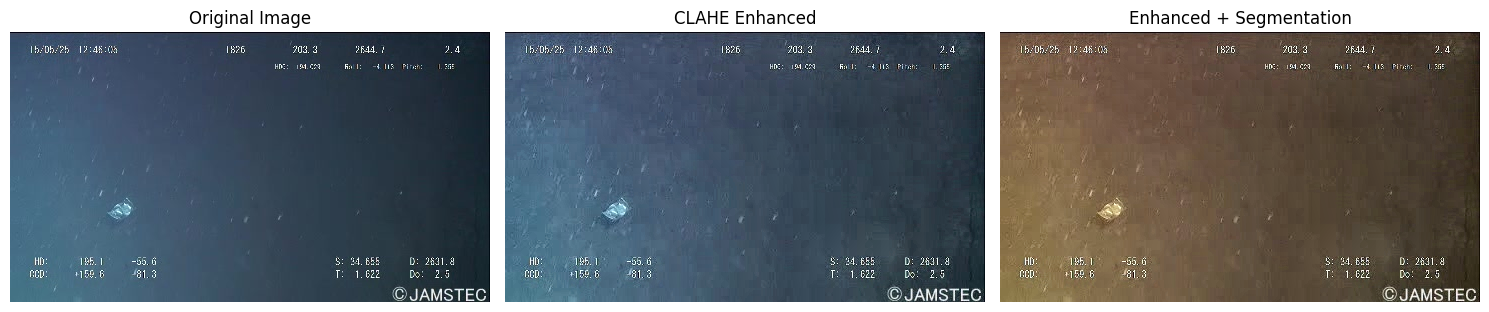

In [16]:
image_path = sample_images[0]

original = cv2.imread(image_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

lab = cv2.cvtColor(original, cv2.COLOR_RGB2LAB)

l, a, b = cv2.split(lab)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced_l = clahe.apply(l)

enhanced = cv2.cvtColor(
    cv2.merge((enhanced_l, a, b)),
    cv2.COLOR_LAB2RGB
)

prediction = best_model.predict(
    source=enhanced,
    conf=0.25
)[0]

segmented = prediction.plot()
segmented = cv2.cvtColor(segmented, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(enhanced)
plt.title("CLAHE Enhanced")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(segmented)
plt.title("Enhanced + Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
import shutil

shutil.copy(
    "/content/underwater_project/waste_segmentation/weights/best.pt",
    "/content/best_underwater_model.pt"
)

shutil.make_archive(
    "/content/underwater_project_results",
    "zip",
    "/content/underwater_project"
)

print("Model and results saved!")

Model and results saved!


In [18]:
from google.colab import files

files.download("/content/best_underwater_model.pt")
files.download("/content/underwater_project_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


image 1/1 /content/dataset/dataset/instance_version/val/vid_000116_frame0000041.jpg: 384x640 1 trash_unknown_instance, 25.4ms
Speed: 3.8ms preprocess, 25.4ms inference, 4.6ms postprocess per image at shape (1, 3, 384, 640)


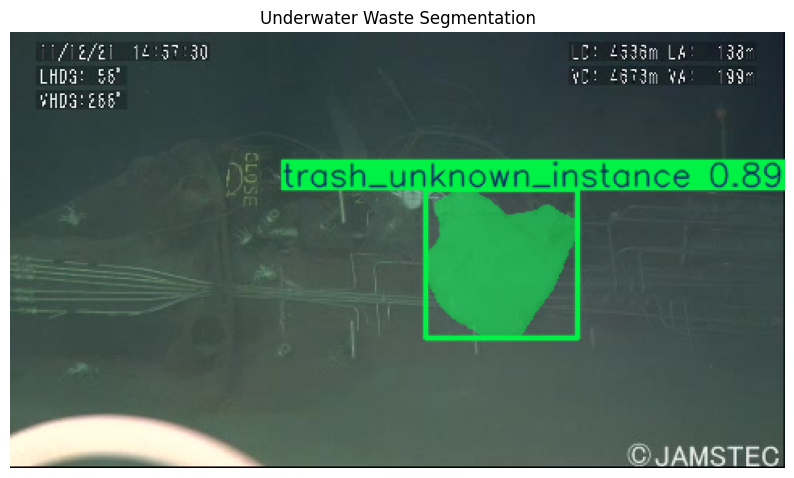


image 1/1 /content/dataset/dataset/instance_version/val/vid_000037_frame0000001.jpg: 384x640 1 trash_unknown_instance, 65.1ms
Speed: 12.0ms preprocess, 65.1ms inference, 3.1ms postprocess per image at shape (1, 3, 384, 640)


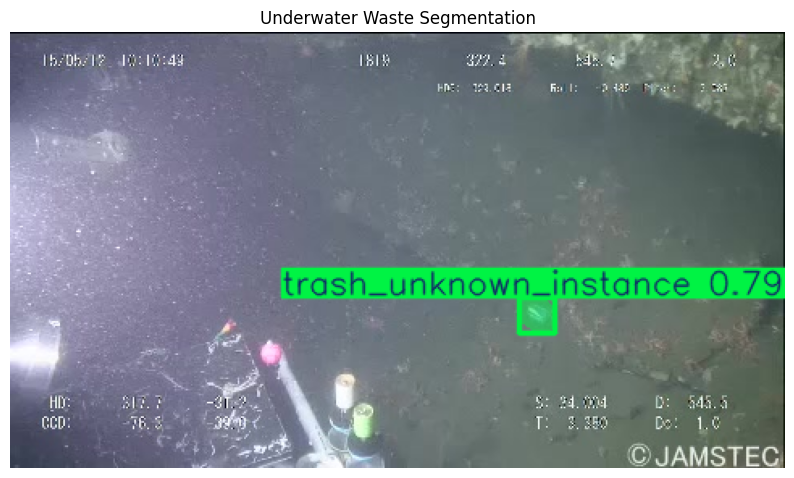


image 1/1 /content/dataset/dataset/instance_version/val/vid_000074_frame0000023.jpg: 384x640 1 trash_unknown_instance, 74.3ms
Speed: 7.8ms preprocess, 74.3ms inference, 9.1ms postprocess per image at shape (1, 3, 384, 640)


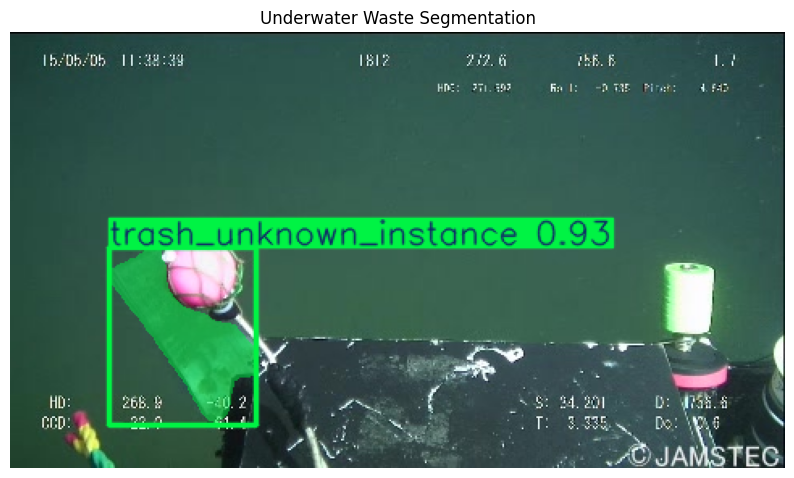


image 1/1 /content/dataset/dataset/instance_version/val/vid_000112_frame0000017.jpg: 480x640 (no detections), 81.9ms
Speed: 10.6ms preprocess, 81.9ms inference, 0.7ms postprocess per image at shape (1, 3, 480, 640)


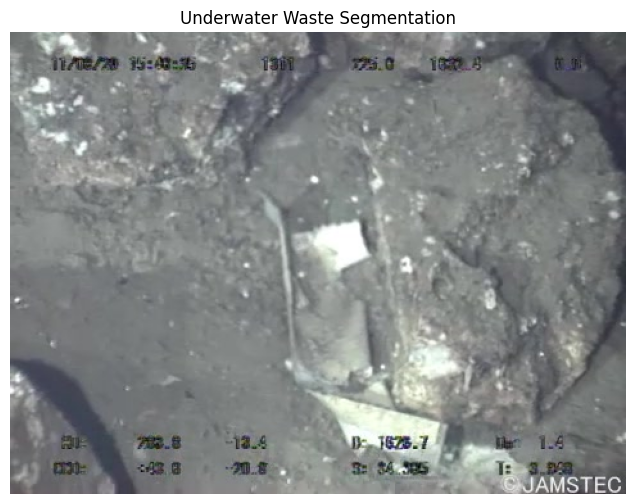

In [19]:

# Display final segmentation predictions

import glob
import random
import cv2
import matplotlib.pyplot as plt

best_model = YOLO(
    "/content/underwater_project/waste_segmentation/weights/best.pt"
)

test_images = glob.glob(
    "/content/dataset/dataset/instance_version/val/*.jpg"
)

sample_images = random.sample(test_images, 4)

for path in sample_images:
    result = best_model.predict(
        source=path,
        conf=0.25
    )[0]

    output = result.plot()

    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title("Underwater Waste Segmentation")
    plt.axis("off")
    plt.show()


In [20]:
from google.colab import userdata

# GitHub username
username = input("Enter GitHub username: ")

# Repository name
repo = "Underwater-Plastic-Waste-Detection"

print("Username:", username)
print("Repository:", repo)

Enter GitHub username: asharma10be24-create
Username: asharma10be24-create
Repository: Underwater-Plastic-Waste-Detection


In [21]:
from google.colab import files

files.download("/content/best_underwater_model.pt")
files.download("/content/underwater_project_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>